# PHẦN 1 — Bài 2 (Trang 28): Khảo sát và Tiền xử lý dữ liệu Bank Marketing

- **Sinh viên thực hiện**: Dương Đại Phát – MSSV: `6451071058` – Lớp: `CQ.64.CNTT`
- **Nguồn dữ liệu**: Bảng mẫu **16 dòng** trích từ tập dữ liệu *Bank Marketing* trong tài liệu thực hành (trang 28–29).
  *(Tham khảo thư mục dữ liệu Google Drive: https://drive.google.com/drive/folders/1rv5SiO5zFlU-cyEXul09OpCvTXrdjG1m?usp=sharing — bài này dùng trực tiếp bảng mẫu 16 dòng trong tài liệu).*
- **Mục tiêu**: Thực hiện khảo sát dữ liệu (`IV.2`) kết hợp đầy đủ 6 bước tiền xử lý theo `IV.1 Yêu cầu cơ bản` (phân loại thuộc tính, xử lý giá trị thiếu, binning & smoothing `Duration`, rời rạc hóa, One-Hot Encoding, chuẩn hóa Min-Max).

## Khởi tạo dữ liệu Bank Marketing (16 mẫu) và Khảo sát dữ liệu ban đầu

In [1]:
print("Dương Đại Phát - 6451071058")
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 120

raw_rows = [
    [1, "housemaid", "Married", "basic.4y", "no", "no", 261, 93.994, "no"],
    [2, "services", "Married", "high.school", "unknown", "no", 149, 93.994, "no"],
    [3, "blue-collar", "Divorced", "basic.4y", "unknown", "no", 1575, 93.994, "yes"],
    [4, "admin.", "Single", "high.school", "no", "no", 338, 93.994, "no"],
    [5, "blue-collar", "Single", "basic.9y", "no", "no", 179, 93.994, "no"],
    [6, "services", "Married", "high.school", "no", "no", 1030, 93.994, "yes"],
    [7, "management", "Married", "high.school", "unknown", "no", 149, np.nan, "no"],
    [8, "unemployed", np.nan, "university.degree", "unknown", "no", 424, 93.994, "no"],
    [9, "technician", "Married", "professional.course", "no", "no", 1623, 93.994, "yes"],
    [10, "services", "Divorced", "high.school", "unknown", "no", 568, 93.994, "no"],
    [11, "blue-collar", "Married", "high.school", "no", "no", 1297, 93.994, "yes"],
    [12, "self-employed", "Married", "basic.9y", "no", "no", 376, 93.918, "no"],
    [13, "entrepreneur", "Married", "professional.course", "no", "yes", 576, 93.994, "no"],
    [14, "services", "Single", "high.school", "no", "no", 1059, 93.200, "yes"],
    [15, "technician", "Married", "basic.9y", "no", "no", 705, 93.200, "yes"],
    [16, "Retired", "Married", "high.school", "no", "no", 532, 93.200, "no"],
]

columns = ["#", "Job", "Marial", "Education", "Default", "Loan", "Duration", "Cons.price.idx", "Subscribe"]
df = pd.DataFrame(raw_rows, columns=columns).set_index("#")

print(f"Kích thước dữ liệu: {df.shape[0]} dòng x {df.shape[1]} cột")
display(df)
print("\n=== THÔNG TIN THUỘC TÍNH (df.info) ===")
df.info()
print("\n=== THỐNG KÊ MÔ TẢ ===")
display(df.describe(include="all"))

Dương Đại Phát - 6451071058


Kích thước dữ liệu: 16 dòng x 8 cột


,Job,Marial,Education,Default,Loan,Duration,Cons.price.idx,Subscribe
#,,,,,,,,
1,housemaid,Married,basic.4y,no,no,261,93.994,no
2,services,Married,high.school,unknown,no,149,93.994,no
3,blue-collar,Divorced,basic.4y,unknown,no,1575,93.994,yes
4,admin.,Single,high.school,no,no,338,93.994,no
5,blue-collar,Single,basic.9y,no,no,179,93.994,no
6,services,Married,high.school,no,no,1030,93.994,yes
7,management,Married,high.school,unknown,no,149,NaN,no
8,unemployed,NaN,university.degree,unknown,no,424,93.994,no
9,technician,Married,professional.course,no,no,1623,93.994,yes



=== THÔNG TIN THUỘC TÍNH (df.info) ===
<class 'pandas.core.frame.DataFrame'>
Index: 16 entries, 1 to 16
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Job             16 non-null     object 
 1   Marial          15 non-null     object 
 2   Education       16 non-null     object 
 3   Default         16 non-null     object 
 4   Loan            16 non-null     object 
 5   Duration        16 non-null     int64  
 6   Cons.price.idx  15 non-null     float64
 7   Subscribe       16 non-null     object 
dtypes: float64(1), int64(1), object(6)
memory usage: 1.1+ KB

=== THỐNG KÊ MÔ TẢ ===


,Job,Marial,Education,Default,Loan,Duration,Cons.price.idx,Subscribe
count,16,15,16,16,16,16.000000,15.000000,16
unique,10,3,5,2,2,NaN,NaN,2
top,services,Married,high.school,no,no,NaN,NaN,no
freq,4,10,8,11,15,NaN,NaN,10
mean,NaN,NaN,NaN,NaN,NaN,677.562500,93.830133,NaN
std,NaN,NaN,NaN,NaN,NaN,493.173258,0.326704,NaN
min,NaN,NaN,NaN,NaN,NaN,149.000000,93.200000,NaN
25%,NaN,NaN,NaN,NaN,NaN,318.750000,93.956000,NaN
50%,NaN,NaN,NaN,NaN,NaN,550.000000,93.994000,NaN
75%,NaN,NaN,NaN,NaN,NaN,1037.250000,93.994000,NaN


Dương Đại Phát - 6451071058
Số lượng giá trị NaN trên mỗi cột:


Job               0
Marial            1
Education         0
Default           0
Loan              0
Duration          0
Cons.price.idx    1
Subscribe         0
dtype: int64

Số lượng giá trị 'unknown' trên các cột chuỗi:


Job               0
Marial            0
Education         0
Default           5
Loan              0
Duration          0
Cons.price.idx    0
Subscribe         0
dtype: int64

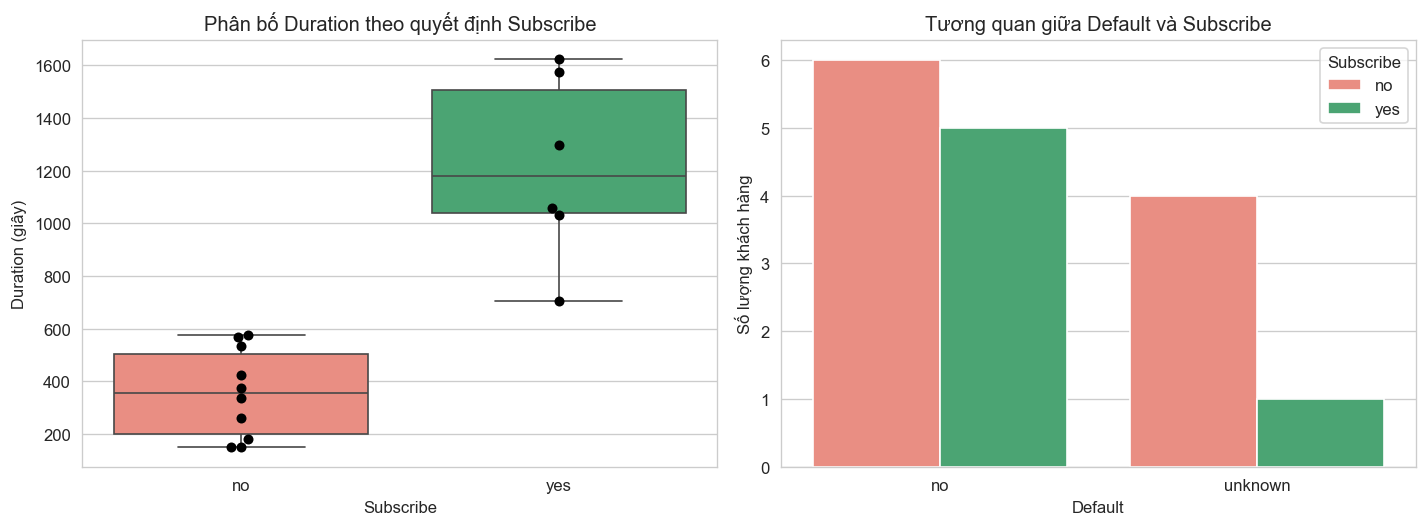

Thống kê Duration theo nhóm Subscribe:


,count,min,mean,median,max
Subscribe,,,,,
no,10,149,355.20,357.0,576
yes,6,705,1214.83,1178.0,1623


In [2]:
print("Dương Đại Phát - 6451071058")
# Khảo sát giá trị thiếu và trực quan hóa mối quan hệ giữa Duration, các thuộc tính phân loại với Subscribe
print("Số lượng giá trị NaN trên mỗi cột:")
display(df.isnull().sum())
print("Số lượng giá trị 'unknown' trên các cột chuỗi:")
display((df == "unknown").sum())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(x="Subscribe", y="Duration", data=df, hue="Subscribe", legend=False, palette={"no": "salmon", "yes": "mediumseagreen"}, ax=axes[0])
sns.swarmplot(x="Subscribe", y="Duration", data=df, color="black", size=6, ax=axes[0])
axes[0].set_title("Phân bố Duration theo quyết định Subscribe")
axes[0].set_ylabel("Duration (giây)")

sns.countplot(x="Default", hue="Subscribe", data=df, palette={"no": "salmon", "yes": "mediumseagreen"}, ax=axes[1])
axes[1].set_title("Tương quan giữa Default và Subscribe")
axes[1].set_ylabel("Số lượng khách hàng")

plt.tight_layout()
plt.show()

print("Thống kê Duration theo nhóm Subscribe:")
display(df.groupby("Subscribe")["Duration"].agg(["count", "min", "mean", "median", "max"]).round(2))

**Nhận xét khảo sát ban đầu:**
- Tập mẫu gồm **16 khách hàng** (`6` người đăng ký `Subscribe = yes` chiếm **37,5%**, `10` người `no` chiếm **62,5%**).
- Có **2 ô bị thiếu thực sự (`NaN`)**: `Cons.price.idx` tại dòng **#7** và `Marial` tại dòng **#8**; ngoài ra thuộc tính `Default` có **5 dòng** mang giá trị `'unknown'` (31,25%).
- **`Duration` là yếu tố phân biệt cực mạnh**: toàn bộ khách hàng `no` có `Duration <= 576` giây (trung bình `355,2s`), trong khi toàn bộ khách hàng `yes` đều có `Duration >= 705` giây (trung bình `1.214,8s`).

## Yêu cầu 1: Phân loại các thuộc tính trong bảng dữ liệu

Dựa theo lý thuyết phân loại thuộc tính dữ liệu (Mục `III.1` trong tài liệu):

| Thuộc tính | Nhóm lớn | Loại chi tiết | Giải thích |
|---|---|---|---|
| `Job` | Định tính (Qualitative) | **Nominal** (Định danh) | Tên nghề nghiệp (`housemaid`, `services`, `blue-collar`, ...), không có thứ tự tự nhiên. |
| `Marial` | Định tính (Qualitative) | **Nominal** (Định danh) | Tình trạng hôn nhân (`Married`, `Single`, `Divorced`), không mang ý nghĩa xếp hạng. |
| `Education` | Định tính (Qualitative) | **Ordinal** (Thứ bậc) | Trình độ học vấn có thứ tự tăng dần: `basic.4y < basic.9y < high.school < professional.course < university.degree`. |
| `Default` | Định tính (Qualitative) | **Nominal** *(gồm `no`, `unknown`)* | Bản chất là nhị phân bất đối xứng (`yes`/`no`), nhưng trong bảng mẫu có thêm nhãn `'unknown'` nên xử lý như Nominal (3 giá trị nếu có `yes`). |
| `Loan` | Định tính (Qualitative) | **Asymmetric Binary** (Nhị phân bất đối xứng) | Chỉ gồm `no` / `yes` (đã có khoản vay hay chưa). |
| `Duration` | Định lượng (Quantitative) | **Ratio-scaled** (Tỉ lệ) | Thời lượng cuộc gọi tính bằng giây, có gốc `0` tuyệt đối (1000s dài gấp đôi 500s). |
| `Cons.price.idx` | Định lượng (Quantitative) | **Interval / Ratio-scaled** | Chỉ số giá tiêu dùng (giá trị số thực liên tục quanh ~93.2–93.994). |
| `Subscribe` | Định tính (Qualitative) | **Asymmetric Binary** *(Thuộc tính quyết định)* | Kết quả mục tiêu (`yes` / `no`) xem khách hàng có đăng ký gửi tiền kỳ hạn hay không. |

In [3]:
print("Dương Đại Phát - 6451071058")
for col in df.columns:
    print(f"- {col:15s} | dtype={str(df[col].dtype):8s} | nunique={df[col].nunique(dropna=True):2d} | values={df[col].dropna().unique().tolist()}")

Dương Đại Phát - 6451071058
- Job             | dtype=object   | nunique=10 | values=['housemaid', 'services', 'blue-collar', 'admin.', 'management', 'unemployed', 'technician', 'self-employed', 'entrepreneur', 'Retired']
- Marial          | dtype=object   | nunique= 3 | values=['Married', 'Divorced', 'Single']
- Education       | dtype=object   | nunique= 5 | values=['basic.4y', 'high.school', 'basic.9y', 'university.degree', 'professional.course']
- Default         | dtype=object   | nunique= 2 | values=['no', 'unknown']
- Loan            | dtype=object   | nunique= 2 | values=['no', 'yes']
- Duration        | dtype=int64    | nunique=15 | values=[261, 149, 1575, 338, 179, 1030, 424, 1623, 568, 1297, 376, 576, 1059, 705, 532]
- Cons.price.idx  | dtype=float64  | nunique= 3 | values=[93.994, 93.918, 93.2]
- Subscribe       | dtype=object   | nunique= 2 | values=['no', 'yes']


## Yêu cầu 2: Xử lý dữ liệu bị thiếu (Missing Values)

In [4]:
print("Dương Đại Phát - 6451071058")
df_clean = df.copy()

# 1. Xử lý thuộc tính số Cons.price.idx (thiếu ở dòng #7, Subscribe='no')
overall_mean_cpi = df_clean["Cons.price.idx"].mean()
class_mean_cpi = df_clean.groupby("Subscribe")["Cons.price.idx"].mean()
print(f"Trung bình toàn bộ Cons.price.idx: {overall_mean_cpi:.4f}")
print("Trung bình Cons.price.idx theo nhóm Subscribe:")
display(class_mean_cpi.round(4))

# Điền theo trung bình cùng thuộc tính quyết định Subscribe='no' (theo hướng dẫn mục IV.1.2)
df_clean["Cons.price.idx"] = df_clean["Cons.price.idx"].fillna(
    df_clean.groupby("Subscribe")["Cons.price.idx"].transform("mean")
).round(3)

# 2. Xử lý thuộc tính phân loại Marial (thiếu ở dòng #8) bằng giá trị xuất hiện nhiều nhất (mode)
mode_marial = df_clean["Marial"].mode()[0]
print(f"Giá trị mode của Marial: '{mode_marial}'")
df_clean["Marial"] = df_clean["Marial"].fillna(mode_marial)

# 3. Đối với Default='unknown' (5 dòng): xem xét giữ 'unknown' như một loại riêng biệt
#    (vì tỷ lệ unknown khá lớn 5/16 = 31.25%), đồng thời minh họa thêm cột Default_mode nếu điền bằng mode.
mode_default = df_clean["Default"].mode()[0]
print(f"Giá trị mode của Default: '{mode_default}' (giữ nguyên 'unknown' làm nhãn riêng trong df_clean)")

print("\nBảng dữ liệu sau khi xử lý giá trị thiếu:")
display(df_clean)
print("Số NaN còn lại:", int(df_clean.isnull().sum().sum()))

Dương Đại Phát - 6451071058
Trung bình toàn bộ Cons.price.idx: 93.8301
Trung bình Cons.price.idx theo nhóm Subscribe:


Subscribe
no     93.8973
yes    93.7293
Name: Cons.price.idx, dtype: float64

Giá trị mode của Marial: 'Married'
Giá trị mode của Default: 'no' (giữ nguyên 'unknown' làm nhãn riêng trong df_clean)

Bảng dữ liệu sau khi xử lý giá trị thiếu:


,Job,Marial,Education,Default,Loan,Duration,Cons.price.idx,Subscribe
#,,,,,,,,
1,housemaid,Married,basic.4y,no,no,261,93.994,no
2,services,Married,high.school,unknown,no,149,93.994,no
3,blue-collar,Divorced,basic.4y,unknown,no,1575,93.994,yes
4,admin.,Single,high.school,no,no,338,93.994,no
5,blue-collar,Single,basic.9y,no,no,179,93.994,no
6,services,Married,high.school,no,no,1030,93.994,yes
7,management,Married,high.school,unknown,no,149,93.897,no
8,unemployed,Married,university.degree,unknown,no,424,93.994,no
9,technician,Married,professional.course,no,no,1623,93.994,yes


Số NaN còn lại: 0


## Yêu cầu 3: Khử nhiễu thuộc tính `Duration` bằng kỹ thuật Binning và làm trơn (Smoothing)

- Giá trị nhỏ nhất của `Duration` là **149**, lớn nhất là **1.623**.
- Chọn khoảng bao **[0, 1800]** với độ rộng mỗi giỏ là **600**, chia thành **3 giỏ (bins)**: `(0, 600]`, `(600, 1200]`, `(1200, 1800]`.
- Tính trung bình từng giỏ rồi thay thế giá trị trong giỏ bằng trung bình giỏ (*smoothing by bin means*).

Dương Đại Phát - 6451071058
Giá trị trung bình của từng giỏ (bin means):


Duration_bin
(0, 600]         355.20
(600, 1200]      931.33
(1200, 1800]    1498.33
Name: Duration, dtype: float64

,Duration,Duration_bin,Duration_smoothed,Subscribe
#,,,,
1,261,"(0, 600]",355.20,no
2,149,"(0, 600]",355.20,no
3,1575,"(1200, 1800]",1498.33,yes
4,338,"(0, 600]",355.20,no
5,179,"(0, 600]",355.20,no
6,1030,"(600, 1200]",931.33,yes
7,149,"(0, 600]",355.20,no
8,424,"(0, 600]",355.20,no
9,1623,"(1200, 1800]",1498.33,yes


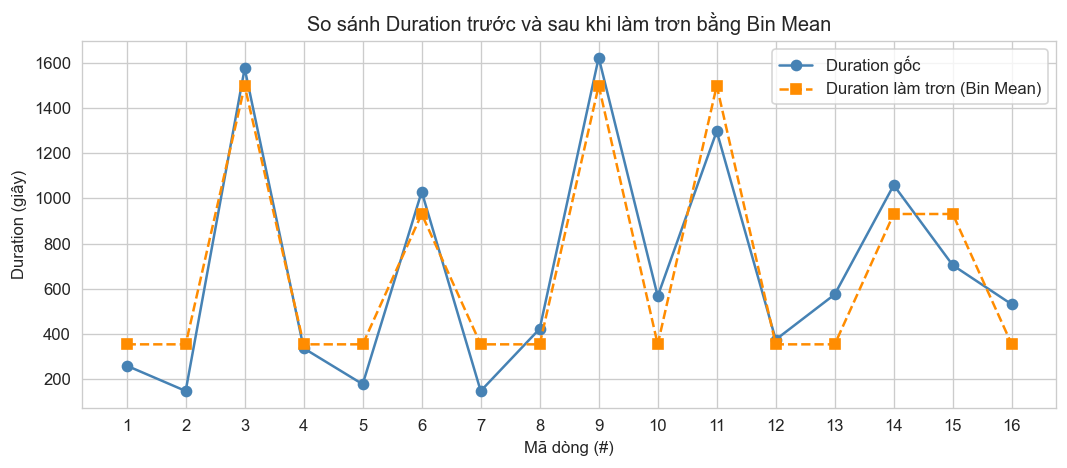

In [5]:
print("Dương Đại Phát - 6451071058")
bins_smooth = [0, 600, 1200, 1800]
df_clean["Duration_bin"] = pd.cut(df_clean["Duration"], bins=bins_smooth)
bin_means = df_clean.groupby("Duration_bin", observed=False)["Duration"].mean().round(2)
print("Giá trị trung bình của từng giỏ (bin means):")
display(bin_means)

df_clean["Duration_smoothed"] = df_clean.groupby("Duration_bin", observed=False)["Duration"].transform("mean").round(2)
display(df_clean[["Duration", "Duration_bin", "Duration_smoothed", "Subscribe"]])

fig, ax = plt.subplots(figsize=(9, 4))
x_idx = df_clean.index
ax.plot(x_idx, df_clean["Duration"], "o-", label="Duration gốc", color="steelblue")
ax.plot(x_idx, df_clean["Duration_smoothed"], "s--", label="Duration làm trơn (Bin Mean)", color="darkorange")
ax.set_xticks(x_idx)
ax.set_xlabel("Mã dòng (#)")
ax.set_ylabel("Duration (giây)")
ax.set_title("So sánh Duration trước và sau khi làm trơn bằng Bin Mean")
ax.legend()
plt.tight_layout()
plt.show()

## Yêu cầu 4: Rời rạc hóa (Discretization) thuộc tính `Duration`

In [6]:
print("Dương Đại Phát - 6451071058")
bins_disc = [0, 300, 600, 1200, 1800]
interval_labels = ["(0, 300]", "(300, 600]", "(600, 1200]", "(1200, 1800]"]
concept_labels = ["Short", "Medium", "Long", "Very Long"]

df_clean["Duration_interval"] = pd.cut(df_clean["Duration"], bins=bins_disc, labels=interval_labels)
df_clean["Duration_concept"] = pd.cut(df_clean["Duration"], bins=bins_disc, labels=concept_labels)

display(df_clean[["Duration", "Duration_interval", "Duration_concept", "Subscribe"]])
print("\nBảng tần suất chéo giữa nhãn khái niệm và Subscribe:")
display(pd.crosstab(df_clean["Duration_concept"], df_clean["Subscribe"], margins=True))

Dương Đại Phát - 6451071058


,Duration,Duration_interval,Duration_concept,Subscribe
#,,,,
1,261,"(0, 300]",Short,no
2,149,"(0, 300]",Short,no
3,1575,"(1200, 1800]",Very Long,yes
4,338,"(300, 600]",Medium,no
5,179,"(0, 300]",Short,no
6,1030,"(600, 1200]",Long,yes
7,149,"(0, 300]",Short,no
8,424,"(300, 600]",Medium,no
9,1623,"(1200, 1800]",Very Long,yes



Bảng tần suất chéo giữa nhãn khái niệm và Subscribe:


Subscribe,no,yes,All
Duration_concept,,,
Short,4,0,4
Medium,6,0,6
Long,0,3,3
Very Long,0,3,3
All,10,6,16


**Nhận xét (Yêu cầu 4):**
- Các khách hàng có thời lượng cuộc gọi thuộc nhóm **`Short` (0–300s)** và **`Medium` (300–600s)** đều có `Subscribe = no` (10/10 trường hợp).
- Ngược lại, tất cả khách hàng ở nhóm **`Long` (600–1200s)** và **`Very Long` (>1200s)** đều có `Subscribe = yes` (6/6 trường hợp).

## Yêu cầu 5: Biểu diễn thuộc tính phân loại bằng One-Hot Encoding

In [7]:
print("Dương Đại Phát - 6451071058")
# Mã hóa thứ bậc cho Education (Ordinal), nhị phân 0/1 cho Loan và Subscribe
edu_order = {
    "basic.4y": 1,
    "basic.9y": 2,
    "high.school": 3,
    "professional.course": 4,
    "university.degree": 5,
}
df_encoded = df_clean[["Job", "Marial", "Education", "Default", "Loan", "Duration", "Cons.price.idx", "Subscribe"]].copy()
df_encoded["Education_ord"] = df_encoded["Education"].map(edu_order)
df_encoded["Loan_bin"] = df_encoded["Loan"].map({"no": 0, "yes": 1})
df_encoded["Subscribe_bin"] = df_encoded["Subscribe"].map({"no": 0, "yes": 1})

# One-Hot Encoding cho các thuộc tính Nominal (Job, Marial, Default) để tránh tạo thứ tự giả 1 < 2 < 3
nominal_cols = ["Job", "Marial", "Default"]
ohe_df = pd.get_dummies(df_encoded[nominal_cols], dtype=int)

df_model = pd.concat(
    [ohe_df, df_encoded[["Education_ord", "Loan_bin", "Duration", "Cons.price.idx", "Subscribe_bin"]]],
    axis=1,
)
print(f"Kích thước bảng sau khi One-Hot Encoding: {df_model.shape}")
display(df_model.head(8))

Dương Đại Phát - 6451071058
Kích thước bảng sau khi One-Hot Encoding: (16, 20)


,Job_Retired,Job_admin.,Job_blue-collar,Job_entrepreneur,Job_housemaid,Job_management,Job_self-employed,Job_services,Job_technician,Job_unemployed,Marial_Divorced,Marial_Married,Marial_Single,Default_no,Default_unknown,Education_ord,Loan_bin,Duration,Cons.price.idx,Subscribe_bin
#,,,,,,,,,,,,,,,,,,,,
1,0,0,0,0,1,0,0,0,0,0,0,1,0,1,0,1,0,261,93.994,0
2,0,0,0,0,0,0,0,1,0,0,0,1,0,0,1,3,0,149,93.994,0
3,0,0,1,0,0,0,0,0,0,0,1,0,0,0,1,1,0,1575,93.994,1
4,0,1,0,0,0,0,0,0,0,0,0,0,1,1,0,3,0,338,93.994,0
5,0,0,1,0,0,0,0,0,0,0,0,0,1,1,0,2,0,179,93.994,0
6,0,0,0,0,0,0,0,1,0,0,0,1,0,1,0,3,0,1030,93.994,1
7,0,0,0,0,0,1,0,0,0,0,0,1,0,0,1,3,0,149,93.897,0
8,0,0,0,0,0,0,0,0,0,1,0,1,0,0,1,5,0,424,93.994,0


## Yêu cầu 6: Chuẩn hóa dữ liệu số bằng Min-Max Normalization

In [8]:
print("Dương Đại Phát - 6451071058")
num_cols = ["Duration", "Cons.price.idx"]
norm_result = df_clean[["Duration", "Cons.price.idx"]].copy()

for col in num_cols:
    col_min = norm_result[col].min()
    col_max = norm_result[col].max()
    norm_result[f"{col}_minmax"] = ((norm_result[col] - col_min) / (col_max - col_min)).round(4)
    print(f"{col}: min = {col_min}, max = {col_max}")

display(norm_result)
print("\nKiểm tra miền giá trị sau Min-Max Normalization:")
display(norm_result[["Duration_minmax", "Cons.price.idx_minmax"]].agg(["min", "max"]))

Dương Đại Phát - 6451071058
Duration: min = 149, max = 1623
Cons.price.idx: min = 93.2, max = 93.994


,Duration,Cons.price.idx,Duration_minmax,Cons.price.idx_minmax
#,,,,
1,261,93.994,0.0760,1.0000
2,149,93.994,0.0000,1.0000
3,1575,93.994,0.9674,1.0000
4,338,93.994,0.1282,1.0000
5,179,93.994,0.0204,1.0000
6,1030,93.994,0.5977,1.0000
7,149,93.897,0.0000,0.8778
8,424,93.994,0.1866,1.0000
9,1623,93.994,1.0000,1.0000



Kiểm tra miền giá trị sau Min-Max Normalization:


,Duration_minmax,Cons.price.idx_minmax
min,0.0,0.0
max,1.0,1.0


**Kết luận (Bài 2 – Trang 28):**
- Sau chuẩn hóa Min-Max, cả hai thuộc tính số có thang đo chênh lệch rất lớn (`Duration` $\in [149, 1623]$ và `Cons.price.idx` $\in [93.200, 93.994]$) đều được đưa về cùng miền $[0, 1]$, sẵn sàng đưa vào các thuật toán nhạy cảm với khoảng cách như k-NN, Neural Networks hoặc k-Means.